In [3]:
import json
import os
import pandas as pd

# 1. Load the CSV files using Pandas
print("Loading datasets...")
zomato_df = pd.read_csv("zomato.csv")
swiggy_df = pd.read_csv("swiggy.csv")


def extract_key_reviews(df, app_name):
    """Filters, sorts, and extracts top positive and negative reviews."""
    # Clean up empty reviews
    df = df.dropna(subset=["review_description"])

    # A. Extract "Bad" Features (1 or 2-star ratings)
    # We sort by 'thumbsUpCount' so we get the complaints that most users agreed with!
    bad_reviews = (
        df[df["rating"] <= 2]
        .sort_values(by="thumbsUpCount", ascending=False)
        .head(10)["review_description"]
        .tolist()
    )

    # B. Extract "Good" Features (5-star ratings)
    good_reviews = (
        df[df["rating"] == 5]
        .sort_values(by="thumbsUpCount", ascending=False)
        .head(10)["review_description"]
        .tolist()
    )

    # C. Missing/Unavailable features (we can seed placeholder gaps to start with)
    unavailable_features = [
        "Cannot order from two different restaurants in a single order",
        "Lack of advanced nutritional/dietary filtering on search results",
        "No integrated option to easily split the bill with friends",
    ]

    return {
        "good_features": good_reviews,
        "bad_features": bad_reviews,
        "unavailable_features": unavailable_features,
    }


# 2. Extract features for both apps
zomato_analysis = extract_key_reviews(zomato_df, "Zomato")
swiggy_analysis = extract_key_reviews(swiggy_df, "Swiggy")

# 3. Read your existing project.json database
database_path = "project.json"
if os.path.exists(database_path):
    with open(database_path, "r") as file:
        db_data = json.load(file)
else:
    db_data = {"users": [], "competitor_analysis": {}, "study_tasks": []}

# 4. Insert the analyzed data into the competitor_analysis section
db_data["competitor_analysis"] = {
    "Zomato": zomato_analysis,
    "Swiggy": swiggy_analysis,
}

# 5. Save the updated database back to project.json
with open(database_path, "w") as file:
    json.dump(db_data, file, indent=4)

print(
    "Successfully processed the datasets and saved the analysis to project.json!"
)

Loading datasets...
Successfully processed the datasets and saved the analysis to project.json!


In [4]:
import os
print("Jupyter is saving files in this folder:")
print(os.getcwd())

# Let's check if 'project.json' exists in this folder
print("\nDoes project.json exist here?", os.path.exists('project.json'))


Jupyter is saving files in this folder:
d:\main_project

Does project.json exist here? True


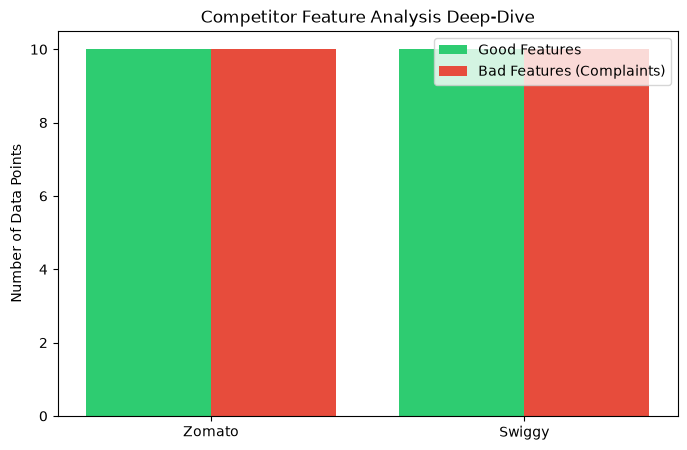

In [5]:
import json
import matplotlib.pyplot as plt

# 1. Load the updated database
with open('project.json', 'r') as file:
    db_data = json.load(file)

comp_data = db_data.get("competitor_analysis", {})

# 2. Extract metrics for visualization
apps = list(comp_data.keys())
good_counts = [len(comp_data[app]["good_features"]) for app in apps]
bad_counts = [len(comp_data[app]["bad_features"]) for app in apps]

# 3. Plot a comparative bar chart
x = range(len(apps))
plt.figure(figsize=(8, 5))
plt.bar([i - 0.2 for i in x], good_counts, width=0.4, label='Good Features', color='#2ecc71')
plt.bar([i + 0.2 for i in x], bad_counts, width=0.4, label='Bad Features (Complaints)', color='#e74c3c')

plt.xticks(x, apps)
plt.ylabel('Number of Data Points')
plt.title('Competitor Feature Analysis Deep-Dive')
plt.legend()
plt.show()